## MERFISH downstream analysis overview

In this section, we demonstrate downstream analysis for the MERFISH dataset.

1. **Patch-level embedding (UMAP)**
   - We first compute a patch-level representation and visualize patches in a **UMAP** space.
   - This helps us inspect how patches organize into distinct **clusters / patch groups**.

2. **Inspecting representative patches**
   - To make the clusters more interpretable, we select **random patches** from each cluster and display them in a grid/matrix.
   - This allows us to compare the **spatial patterns** and the “real” appearance of patches across different patch groups.

3. **Sample-level analysis with PILOT**
   - Next, we use **PILOT** for sample-level analysis.
   - We visualize the **trajectory of samples** and relate each sample to its **corresponding tissue**.
   - Samples/tissues are colored by their **dominant patch cluster composition**, making it easier to connect patch-level structure to higher-level biological organization.

📌 **PILOT**  
PILOT documentation: https://pilot.readthedocs.io/en/latest/


In [3]:
from pilotpy.tools import *
from pilotpy.plot import *
import os

In [4]:
desired_path = '/data/mu0611151/data/mask/Paul/Github/HeartNet/analysis/'

In [8]:
merfish=sc.read_h5ad('/data/scRNA/To_Mehdi/pan_data/his_seems_last_version/Merfish_v0.h5ad')
merfish.obs["Sample_IDs"] = merfish.obs["match_id"].str.extract(r"(^.*?\.ome)")
merfish=merfish[~merfish.obs['Sample_IDs'].isin(['T20-07103-I-1_region_1.ome', 'T20-07103-I-1_region_2.ome', 'T21-09706_region_0.ome'])].copy() 

In [11]:
merfish.obs['diagnosis_CK'].unique()

['control', 'ICM', 'ICM_AMI']
Categories (3, object): ['ICM', 'ICM_AMI', 'control']

In [12]:
wasserstein_distance(merfish,emb_matrix='X_pca_harmony',
clusters_col='patch_annotation',sample_col='Sample_IDs',status='diagnosis_CK',metric='euclidean')

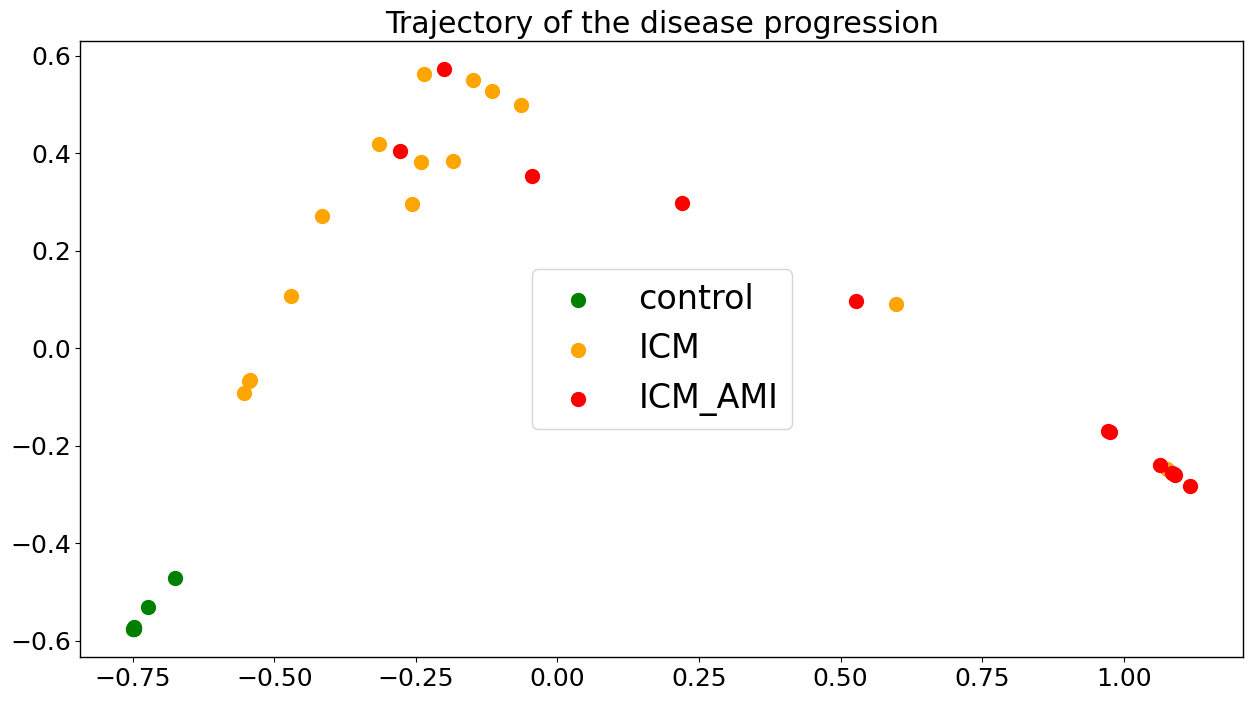

In [13]:
trajectory(merfish,colors=['green','orange','red','blue'],label_act=False,font_size=18,knn=10,figsize=(15,8))

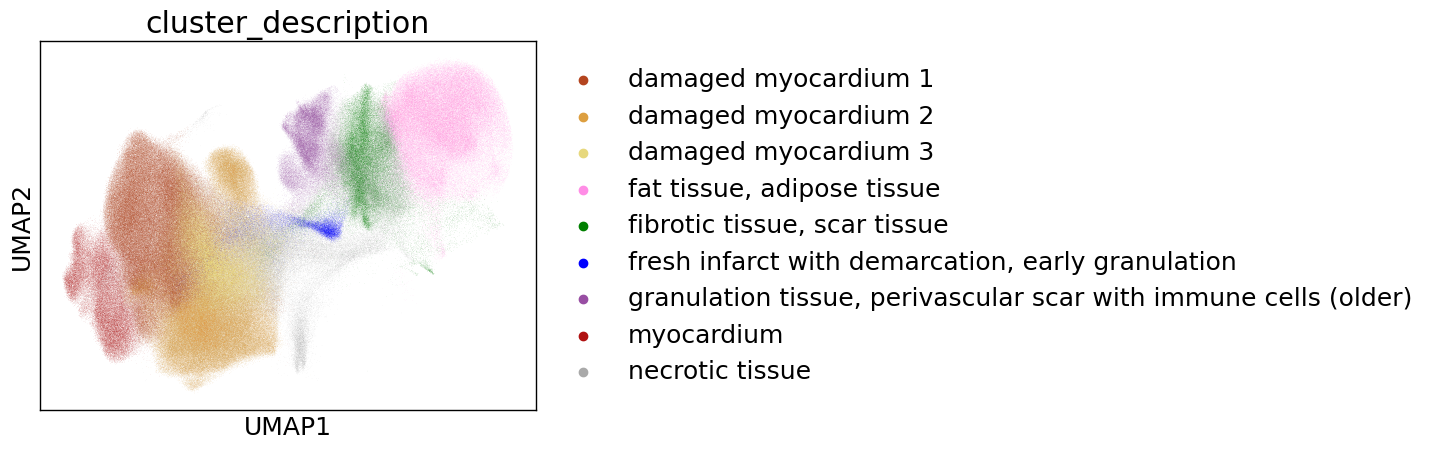

In [14]:
merfish.obs['cluster_description'] = merfish.obs['patch_annotation'].astype(str)
merfish.obs['cluster_description'] = merfish.obs['cluster_description'].astype('category')

class_to_color = {
     "damaged myocardium 1": "#b4451f",
    "damaged myocardium 2": "#dd9f40",
    "fat tissue, adipose tissue": "#FF8DE6",
    "damaged myocardium 3": "#e7d87d",
    "fibrotic tissue, scar tissue": "green",
    "necrotic tissue": "#A9A9A9",
    "myocardium": "#b01111",
    "granulation tissue, perivascular scar with immune cells (older)": "#984ea3",
    "fresh infarct with demarcation, early granulation": "blue",
}


leiden_labels = list(merfish.obs['cluster_description'].cat.categories)
merfish.uns['cluster_description_colors'] = [class_to_color[label] for label in leiden_labels]
sc.pl.umap(merfish, color=['cluster_description'])

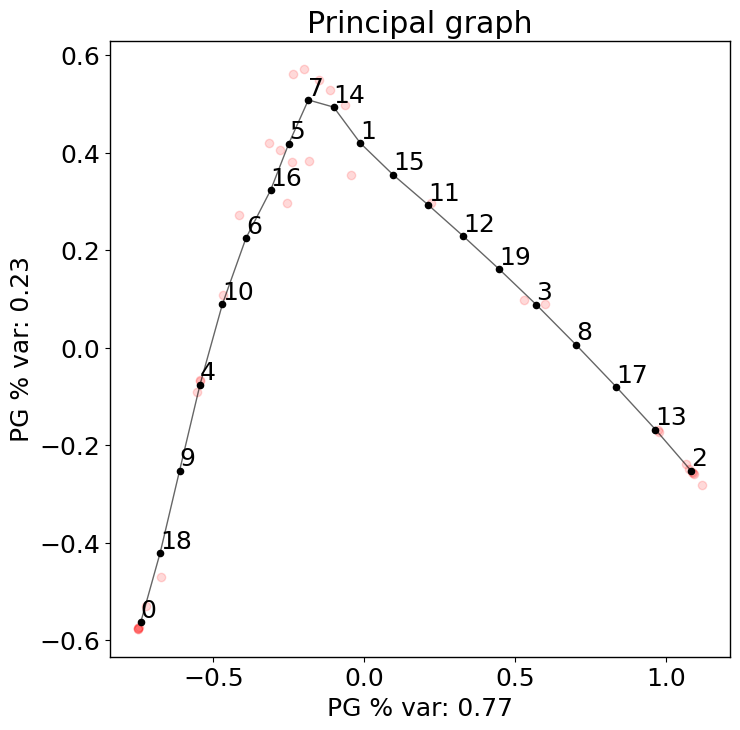

In [18]:
fit_pricipla_graph(merfish, source_node =0,figsize=(8,8))

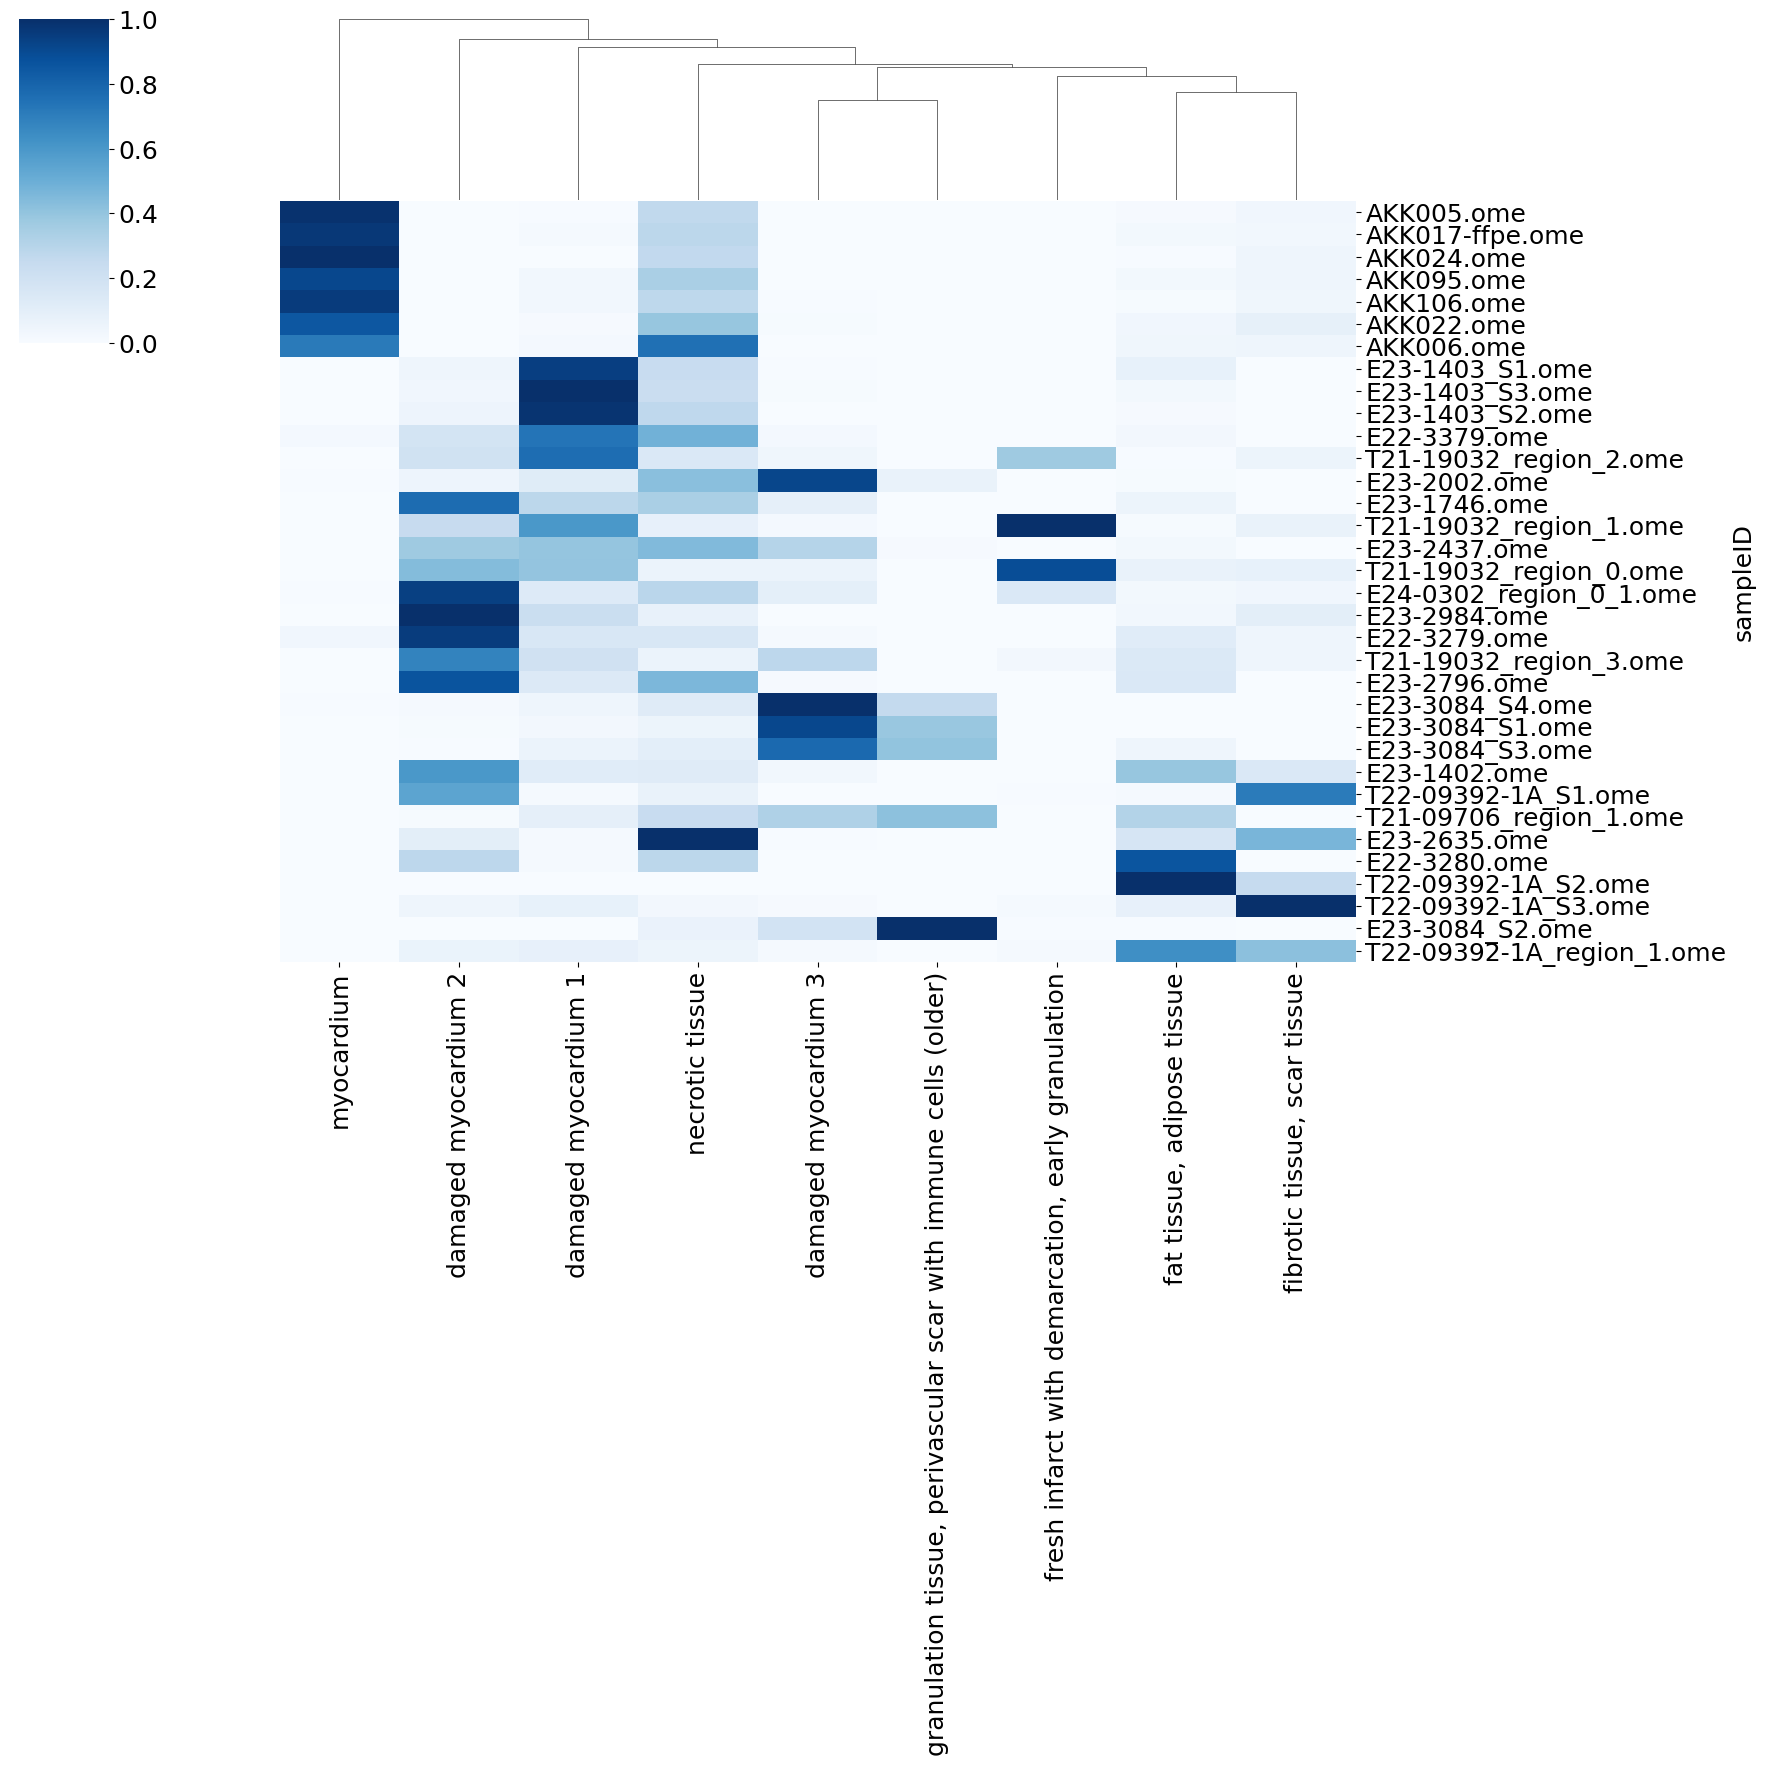

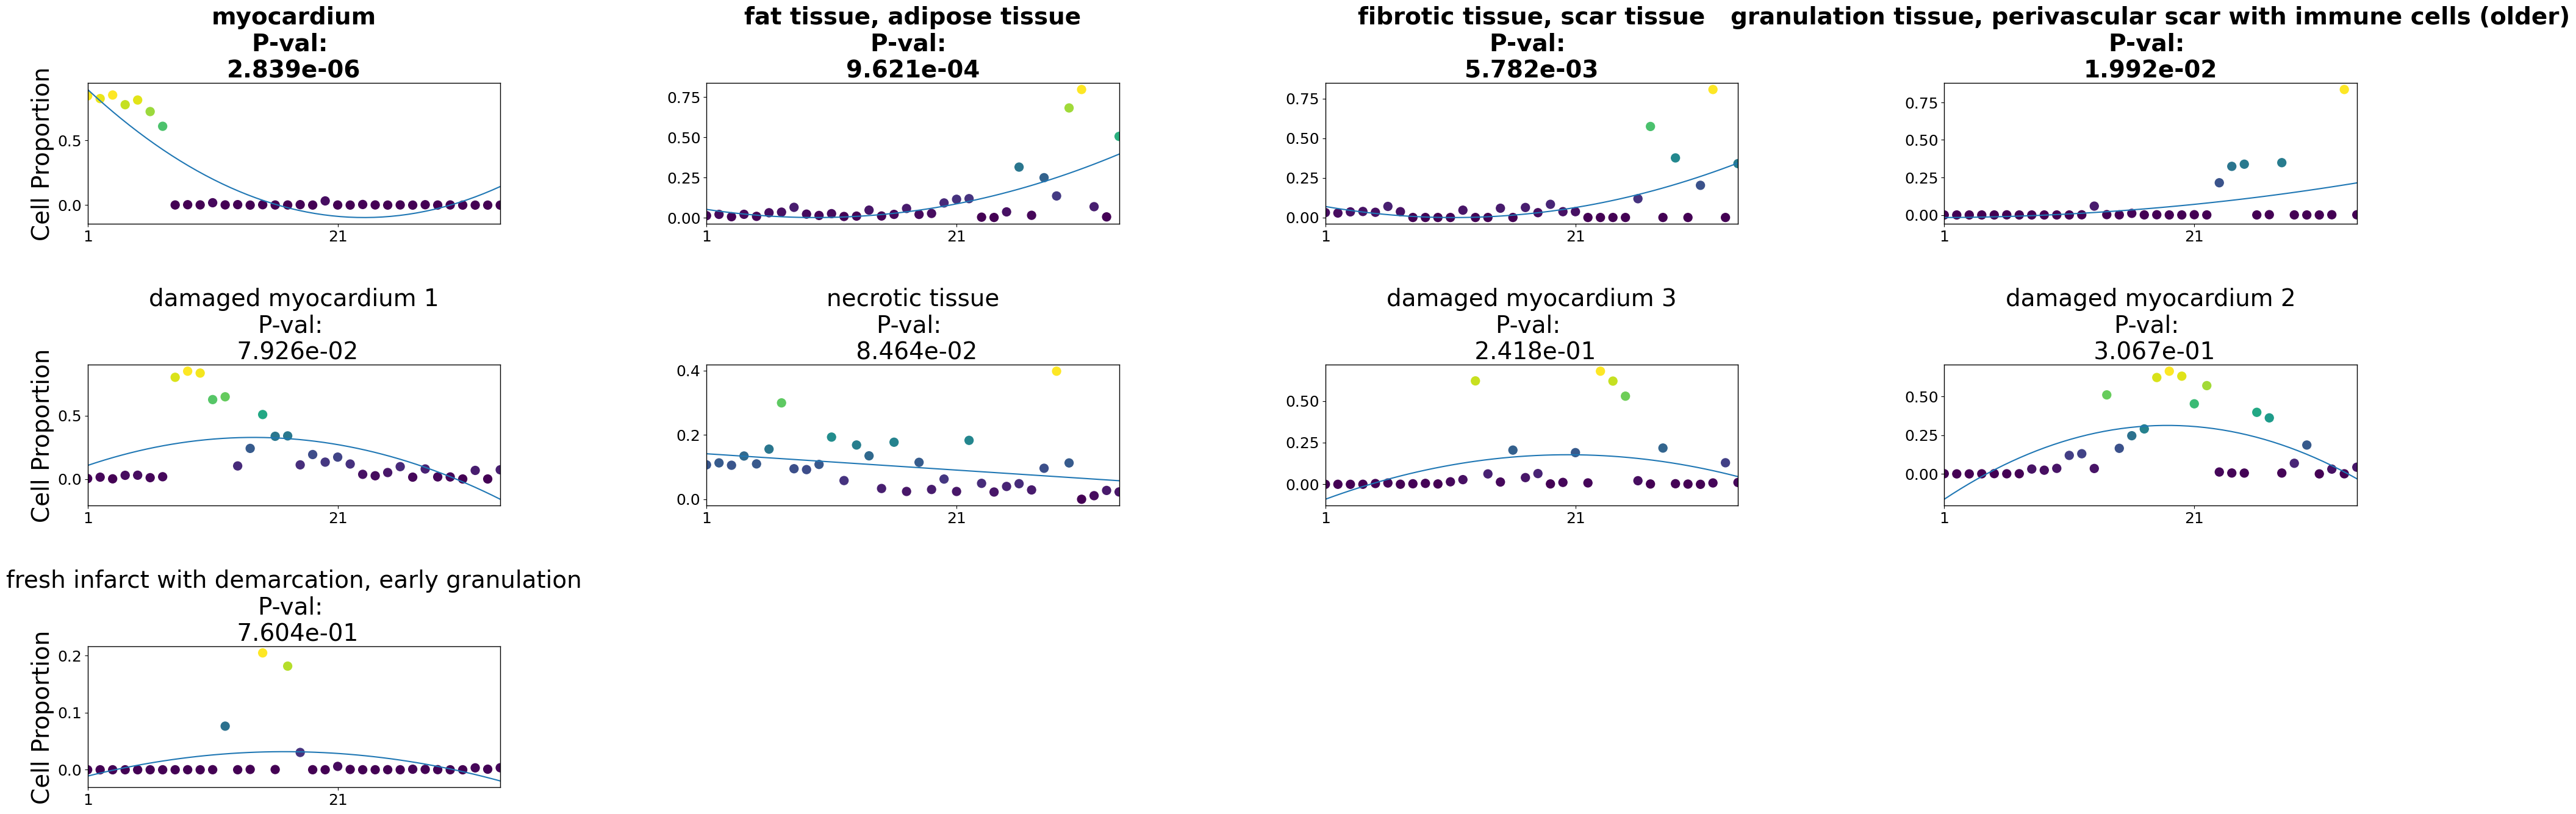

In [21]:

cell_importance(merfish,height=15,width=48,fontsize=28,xlim=20,figsize=(18,18))

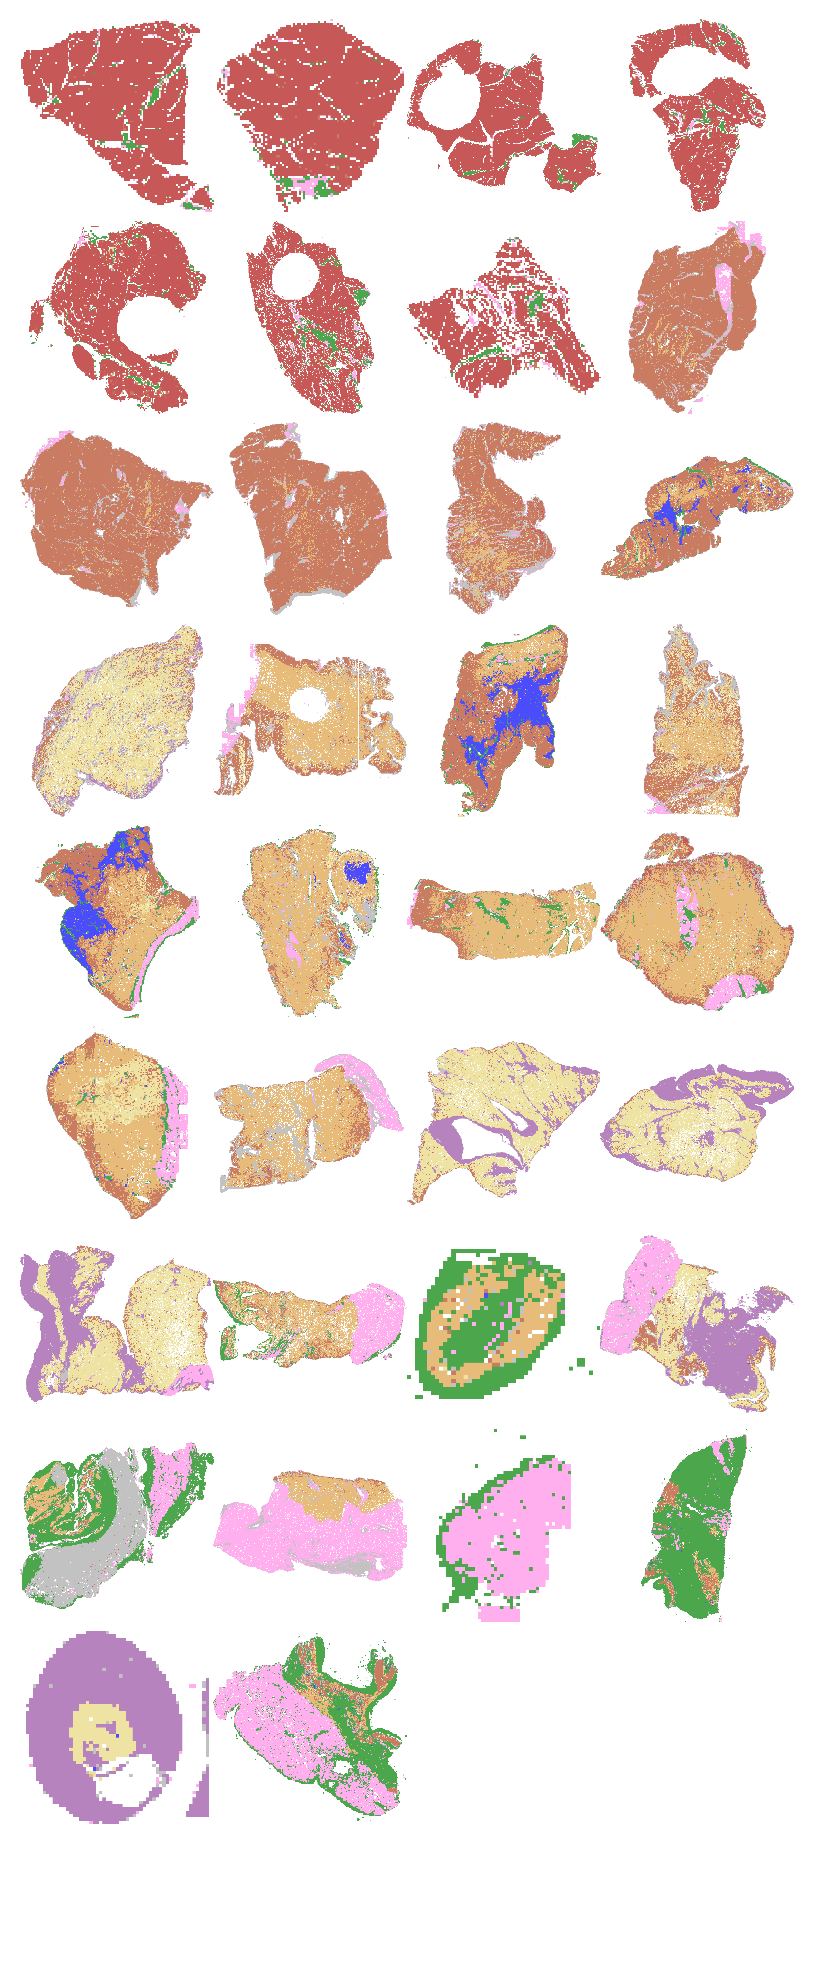

Saved grid with 34 images to Results_PILOT/Cores_based_his_only.pdf


In [23]:
merfish.uns['orders'].rename(columns={'Time_score': 'pseudotime'}, inplace=True)
create_sample_grid(df=merfish.uns['orders'],image_dir='/data/scRNA/To_Mehdi/pan_data/spatial/colored_patches_clusters_with_xenium_clusters_cleaning_annotations/', output_path="Results_PILOT/Cores_based_his_only.pdf")

In [22]:
import math
import os
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

def create_sample_grid(df, image_dir='/data/scRNA/To_Mehdi/pan_data/xei/Human/colored_patches_cluters_/', 
                      output_path="Results_PILOT/Histology_figures/sample_grid_cores.pdf", 
                      zoom=0.15, num_rows=10):
    """
    Create a grid of sample images based on ordering in a DataFrame.
    
    Args:
        df: DataFrame containing at least:
            - 'sampleID': unique sample identifiers
            - 'order': numerical ordering for sorting
        image_dir: Directory containing images (named as {sampleID}.png)
        output_path: Where to save the resulting grid
        zoom: Zoom level for images
        num_rows: Number of rows in the grid
    """
    # Sort samples by the specified order
    sorted_df = df.sort_values('pseudotime')
    sample_names = [name.replace('.ome', '') for name in sorted_df['sampleID'].tolist()]
    
    # Filter out samples that don't have corresponding PNG files
    valid_samples = []
    for sample in sample_names:
        img_path = os.path.join(image_dir, f"{sample}.png")
        if os.path.exists(img_path):
            valid_samples.append(sample)
        else:
            print(f"Warning: Image not found for sample {sample} at {img_path}")
    
    num_samples = len(valid_samples)
    
    if num_samples == 0:
        print("No valid images found!")
        return
    
    # Calculate grid dimensions
    num_cols = math.ceil(num_samples / num_rows)
    
    # Prepare figure
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 2, num_rows * 2))
    
    # Flatten axes array for easier indexing
    if num_rows > 1 or num_cols > 1:
        axes = axes.flatten()
    else:
        axes = [axes]
    
    # Plot each valid sample
    for i, sample in enumerate(valid_samples):
        img_path = os.path.join(image_dir, f"{sample}.png")
        ax = axes[i]
        
        # Add image
        img = OffsetImage(plt.imread(img_path), zoom=zoom)
        ab = AnnotationBbox(img, (0.5, 0.5), 
                          frameon=False, 
                          box_alignment=(0.5, 0.5))
        ax.add_artist(ab)
        
        # Minimal labeling
       # ax.set_title(sample, fontsize=6)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.axis('off')
    
    # Hide unused subplots
    for i in range(num_samples, len(axes)):
        axes[i].axis('off')
    
    plt.tight_layout()
    
    # Create output directory if it doesn't exist
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    
    fig.canvas.draw()  # Force render
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Saved grid with {num_samples} images to {output_path}")